<a href="https://colab.research.google.com/github/EOONU/ml-campus-walk-data-project-colab/blob/main/Python_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import pandas as pd


In [4]:
df = pd.read_csv(
 '/content/drive/MyDrive/Colab Notebooks/brah/CampusWalkDataset_TemplateIDs.csv'

)

In [23]:
print ('the shape (rows x cols) of my dataset array\n' )
print(df.shape)
print('\nThe first 5 rows of my datasheet:\n')
print(df.head())

the shape (rows x cols) of my dataset array

(199, 23)

The first 5 rows of my datasheet:

  recorder_id        date                        location        weather  \
0     R26_001  22/09/2026                L01 MainEntrance  Partly cloudy   
1     R26_001  22/09/2026                L02 LibraryGreen          Sunny   
2     R26_001  22/09/2026   L06 HedgingBehindSportsCentre  Partly cloudy   
3     R26_001  22/09/2026  L08 AccessRoadNearSportsCentre  Partly cloudy   
4     R26_001  22/09/2026   L06 HedgingBehindSportsCentre          Sunny   

  temperature_c sound level foot_traffic primary_sound_type_urban  \
0            16       Quiet          Low             Human voices   
1            16    Moderate          Low                  Traffic   
2            16       Quiet          Low             Construction   
3            16    Moderate          Low             Human voices   
4            16    Moderate          Low                  Traffic   

  other_sound_type_urban primary_soun

In [29]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Load dataset
df = pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/brah/CampusWalkDataset_TemplateIDs.csv',
    header=4
)

# Remove extra spaces and blank cells
df = df.replace(r'^\s*$', pd.NA, regex=True)

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Remove rows containing only an ID
df = df.dropna(subset=df.columns[1:], how='all')

# Remove completely empty columns
df = df.dropna(axis=1, how='all')

# Reset row numbers
df = df.reset_index(drop=True)

# Standardise weather
df['weather'] = df['weather'].str.lower().replace({
    'sunny': 'Sunny',
    'cloudy': 'Cloudy',
    'partly cloudy': 'Partly cloudy',
    'windy': 'Windy',
    'rainy': 'Rainy'
})

# Fix ease rating spelling
df['ease_rating'] = df['ease_rating'].replace({
    'Vey easy': 'Very easy',
    'vey easy': 'Very easy',
    'Slighly uneasy': 'Slightly uneasy',
    'slighly uneasy': 'Slightly uneasy'
})

# Clean temperature (remove C and °C)
df['temperature_c'] = (
    df['temperature_c']
    .astype(str)
    .str.replace('°C', '', regex=False)
    .str.replace('C', '', regex=False)
    .str.strip()
)

df['temperature_c'] = pd.to_numeric(
    df['temperature_c'],
    errors='coerce'
)

# Standardise nature connection rating
df['nature_connection_experience_rating'] = (
    df['nature_connection_experience_rating']
    .replace({
        'same': 'No change',
        'Same': 'No change'
    })
)

# Standardise sound level
df['sound level'] = df['sound level'].replace({
    'quiet': 'Quiet',
    'moderate': 'Moderate',
    'loud': 'Loud'
})

# Convert counts to numeric
for col in ['insects_count', 'birds_count']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill missing text values with Other
text_cols = df.select_dtypes(include=['object', 'string']).columns
df[text_cols] = df[text_cols].fillna('Other')

# Keep missing numeric values as NaN
# rather than replacing measurements with text

# Display cleaned dataset
print("Cleaned dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())

display(df)

Cleaned dataset shape: (135, 23)
Missing values: 0


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16.0,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,Other
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16.0,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,Other,Some,Other,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,Other
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16.0,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,Other,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,Other
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16.0,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,Other,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,Other
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16.0,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,Other,Some,Other,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,Other
5,R26_002,22/09/2026,L01 MainEntrance,Sunny,17.0,Moderate,Low,Traffic,Human voices,Other birds,Insects,2.0,4.0,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
6,R26_002,22/09/2026,L04 PathFrontiHub,Windy,17.0,Moderate,Low,Traffic,Other,Wind,Insects,2.0,2.0,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,Other
7,R26_002,22/09/2026,L05 GreenFrontSportsCentre,Sunny,19.0,Moderate,Low,Traffic,Service machinery,Wind,Other,7.0,0.0,Many,Many,Many,Many,Positive wellbeing,Very easy,Mostly calm,Much more connected,wild plants,Other
8,R26_002,22/09/2026,L06 HedgingBehindSportsCentre,Cloudy,16.0,Quiet,Low,Traffic,Human voices,Wind,Trees,3.0,1.0,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,Other
9,R26_002,22/09/2026,L07 CarParkNearSportsCentre,Sunny,18.0,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6.0,2.0,Many,Many,Many,Some,Very positive wellbeing,Very easy,Very calm,Much more connected,insects,Other


number of observations, averages, minimums, maximums and most common categories

In [31]:
# Summary of the cleaned dataset
print("Dataset dimensions:")
print(df.shape)

print("\nColumn information:")
df.info()

print("\nNumerical statistics:")
display(df.describe())

print("\nCategorical statistics:")
display(df.describe(include=['object', 'string']))

Dataset dimensions:
(135, 23)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            135 non-null    object 
 1   date                                   135 non-null    object 
 2   location                               135 non-null    object 
 3   weather                                135 non-null    object 
 4   temperature_c                          135 non-null    float64
 5   sound level                            135 non-null    object 
 6   foot_traffic                           135 non-null    object 
 7   primary_sound_type_urban               135 non-null    object 
 8   other_sound_type_urban                 135 non-null    object 
 9   primary_sound_type_nature              135 non-null    object 
 10  other_sound_type_nature

,temperature_c,insects_count,birds_count
count,135.000000,135.000000,135.000000
mean,16.648148,2.733333,1.992593
std,1.345354,5.106624,2.789897
min,10.000000,0.000000,0.000000
25%,16.000000,0.000000,0.000000
50%,17.000000,1.000000,1.000000
75%,17.000000,3.000000,3.000000
max,19.000000,31.000000,20.000000



Categorical statistics:


,recorder_id,date,location,weather,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
count,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135,135
unique,28,8,9,4,3,4,5,5,6,6,3,3,3,3,5,5,5,4,82,59
top,R26_021,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,Moderate,Low,Traffic,Human voices,Wind,Trees,Many,Some,Some,Some,Positive wellbeing,Easy,Mostly calm,A little more connected,Other,Other
freq,6,66,27,84,60,95,78,69,79,51,101,78,60,65,69,58,59,42,15,68


Count observations at each location

,count
location,
L06 HedgingBehindSportsCentre,27
L01 MainEntrance,23
L05 GreenFrontSportsCentre,19
L04 PathFrontiHub,18
L07 CarParkNearSportsCentre,15
L02 LibraryGreen,14
L03 LowerSidePathiHub,9
L08 AccessRoadNearSportsCentre,7
L10 OtherOffCampus,3


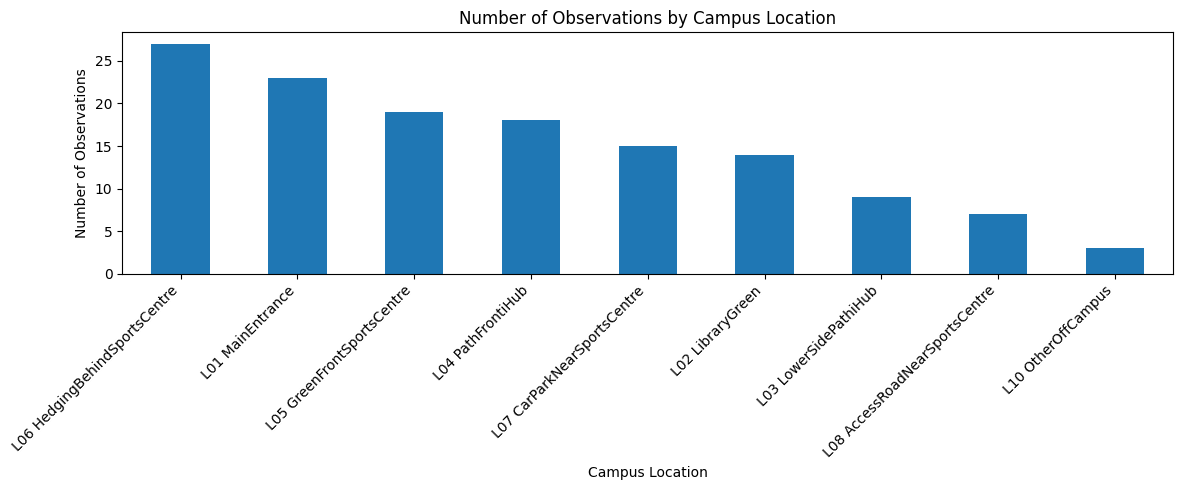

In [34]:
import matplotlib.pyplot as plt
location_counts = df['location'].value_counts()

display(location_counts)


df['location'].value_counts().plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Number of Observations by Campus Location')
plt.xlabel('Campus Location')
plt.ylabel('Number of Observations')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Sound levels

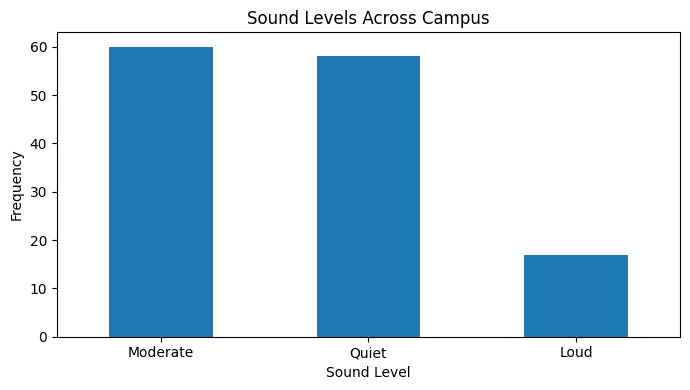

In [35]:
df['sound level'].value_counts().plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Sound Levels Across Campus')
plt.xlabel('Sound Level')
plt.ylabel('Frequency')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

wildlife average counts

In [37]:
wildlife = df.groupby('location')[
    ['insects_count', 'birds_count']
].mean()

display(wildlife.round(2))

,insects_count,birds_count
location,,
L01 MainEntrance,1.48,2.52
L02 LibraryGreen,1.29,2.00
L03 LowerSidePathiHub,0.67,0.78
L04 PathFrontiHub,1.44,1.78
L05 GreenFrontSportsCentre,3.74,0.79
L06 HedgingBehindSportsCentre,4.04,3.33
L07 CarParkNearSportsCentre,6.33,2.13
L08 AccessRoadNearSportsCentre,1.00,0.86
L10 OtherOffCampus,1.00,0.33


In [30]:
output = '/content/drive/MyDrive/Colab Notebooks/brah/CampusWalk_Cleaned.csv'

df.to_csv(output, index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
